This notebook is created for hardware Validation on IBM Quantum Hardware 

# hardware_validation.ipynb : IBM hardware validation

Backend: ibm_fez. Jobs: dbs9lbok09pc73avthe0 (8-task, 5 circuits),
dbs9pmejjaos73ajua20 (4-task, 1 circuit).
Total QPU: ~10 seconds. All counts saved under `hardware_results/`.

In [1]:
import pandas as pd
import importlib.metadata
from qiskit_ibm_runtime import QiskitRuntimeService

try:
    from qiskit_ibm_runtime.executor_sampler import (
        Sampler as HardwareSampler
    )
    sampler_implementation = "Client-side Sampler V2"
except ImportError:
    from qiskit_ibm_runtime import (
        SamplerV2 as HardwareSampler
    )
    sampler_implementation = "SamplerV2"

print(
    "Qiskit:",
    importlib.metadata.version("qiskit"),
)
print(
    "IBM Runtime:",
    importlib.metadata.version("qiskit-ibm-runtime"),
)
print("Sampler:", sampler_implementation)



service = QiskitRuntimeService()

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=8,
)

status = backend.status()

print("Backend:", backend.name)
print("Physical qubits:", backend.num_qubits)
print("Operational:", status.operational)
print("Pending jobs:", status.pending_jobs)
print("Connection successful. No quantum job submitted.")

Qiskit: 2.6.2
IBM Runtime: 0.52.1
Sampler: Client-side Sampler V2
Backend: ibm_fez
Physical qubits: 156
Operational: True
Pending jobs: 0
Connection successful. No quantum job submitted.


Preparing the right task ciruit locally 

In [2]:
from pathlib import Path
import json
import numpy as np

from qiskit import qpy
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

ROOT = Path(
    "/Users/drsweetyramnani/Documents/Research_Projects/Quantum"
)
OUT = ROOT / "hardware_results"
OUT.mkdir(exist_ok=True)

# Read your saved scenario, without rerunning the old notebook.
source_path = ROOT / "multi_scenario_report.json"
source_report = json.loads(source_path.read_text())
scenario = source_report["scenarios"]["original"]

tasks_hw = scenario["tasks"]
conflicts_hw = scenario["conflicts"]
variable_names_hw = [task["id"] for task in tasks_hw]

SEED = 0
REPS = 1
PENALTY = 20.0

qp_hw = QuadraticProgram("Original_Hardware_Test")
for name in variable_names_hw:
    qp_hw.binary_var(name=name)

qp_hw.minimize(
    linear={
        task["id"]: -task["priority"]
        for task in tasks_hw
    },
    quadratic={
        tuple(pair): PENALTY
        for pair in conflicts_hw
    },
)

# Optimize locally. Hardware will evaluate the resulting circuit.
local_qaoa = QAOA(
    sampler=StatevectorSampler(
        default_shots=1024,
        seed=SEED,
    ),
    optimizer=COBYLA(maxiter=100),
    reps=REPS,
    initial_point=np.random.default_rng(SEED).uniform(
        0, np.pi, 2 * REPS
    ),
)

local_result = MinimumEigenOptimizer(local_qaoa).solve(qp_hw)
parameters_hw = (
    local_result.min_eigen_solver_result.optimal_point
)

logical_circuit = local_qaoa.ansatz.assign_parameters(
    parameters_hw
)
logical_circuit = logical_circuit.remove_final_measurements(
    inplace=False
)
logical_circuit.measure_all()

# Mapping the eight logical qubits onto the physical device.
pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=SEED,
)
isa_circuit = pass_manager.run(logical_circuit)

two_qubit_gates = sum(
    instruction.operation.num_qubits == 2
    for instruction in isa_circuit.data
    if instruction.operation.name != "barrier"
)

assert logical_circuit.num_qubits == 8
assert isa_circuit.num_clbits == 8
assert isa_circuit.num_parameters == 0

hardware_manifest = {
    "scenario": "original",
    "backend": backend.name,
    "tasks": tasks_hw,
    "conflicts": conflicts_hw,
    "variable_order": variable_names_hw,
    "seed": SEED,
    "reps": REPS,
    "penalty": PENALTY,
    "local_maxiter": 100,
    "local_shots": 1024,
    "optimal_parameters": parameters_hw.tolist(),
    "optimizer_returned_fval": float(local_result.fval),
    "isa_depth": isa_circuit.depth(),
    "isa_two_qubit_gates": int(two_qubit_gates),
    "versions": {
        package: importlib.metadata.version(package)
        for package in [
            "qiskit",
            "qiskit-ibm-runtime",
            "qiskit-algorithms",
            "qiskit-optimization",
        ]
    },
}

with (OUT / "original_test_circuits.qpy").open("wb") as file:
    qpy.dump([logical_circuit, isa_circuit], file)

(OUT / "original_test_manifest.json").write_text(
    json.dumps(hardware_manifest, indent=2)
)

print("Local optimizer returned fval:", local_result.fval)
print("Logical qubits:", logical_circuit.num_qubits)
print("Classical measurement bits:", isa_circuit.num_clbits)
print("Transpiled depth:", isa_circuit.depth())
print("Two-qubit gates:", two_qubit_gates)
print("Circuit saved. No hardware job submitted yet.")

/Users/drsweetyramnani/Documents/Research_Projects/Quantum/qiskit-env/lib/python3.14/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/Users/drsweetyramnani/Documents/Research_Projects/Quantum/qiskit-env/lib/python3.14/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/Users/drsweetyramnani/Documents/Research_Projects/Quantum/qiskit-env/lib/python3.14/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Local optimizer returned fval: -22.0
Logical qubits: 8
Classical measurement bits: 8
Transpiled depth: 80
Two-qubit gates: 30
Circuit saved. No hardware job submitted yet.


running hardware test with 256 shots

In [3]:
job_file = OUT / "original_test_job.json"

if job_file.exists():
    saved_job = json.loads(job_file.read_text())
    hardware_job = service.job(saved_job["job_id"])
    print("Recovered existing job:", saved_job["job_id"])
else:
    hardware_sampler = HardwareSampler(
        mode=backend,
        options={"max_execution_time": 120},
    )

    hardware_job = hardware_sampler.run(
        [isa_circuit],
        shots=256,
    )

    job_info = {
        "job_id": hardware_job.job_id(),
        "backend": backend.name,
        "shots": 256,
        "manifest": "original_test_manifest.json",
    }
    job_file.write_text(json.dumps(job_info, indent=2))

    print("Submitted job:", hardware_job.job_id())

print("Status:", hardware_job.status())
print("Job information saved to:", job_file)

Submitted job: dbs9lbok09pc73avthe0
Status: QUEUED
Job information saved to: /Users/drsweetyramnani/Documents/Research_Projects/Quantum/hardware_results/original_test_job.json


In [4]:
hardware_job = service.job("dbs9lbok09pc73avthe0")
print("Current status:", hardware_job.status())

Current status: DONE


In [5]:
hardware_result = hardware_job.result()
hardware_counts = hardware_result[0].data.meas.get_counts()

print("Shots received:", sum(hardware_counts.values()))
print("Most frequent outcomes:")
for bits, count in sorted(
    hardware_counts.items(),
    key=lambda item: item[1],
    reverse=True,
)[:10]:
    print(bits, count)

# Save the measurements immediately.
(OUT / "original_test_counts.json").write_text(
    json.dumps(hardware_counts, indent=2)
)

print("Counts saved.")

Shots received: 256
Most frequent outcomes:
00100010 8
00101010 7
10110010 6
10000000 5
00101011 5
10000010 4
00111010 4
00000110 4
10100100 4
00111000 4
Counts saved.


In [7]:
from itertools import product
from qiskit.quantum_info import Statevector

names = hardware_manifest["variable_order"]
tasks = hardware_manifest["tasks"]
conflicts = hardware_manifest["conflicts"]

def score_outcome(bitstring):
    # Rightmost measured bit corresponds to task variable 0.
    values = bitstring.replace(" ", "")[::-1]
    assert len(values) == len(names)

    decisions = dict(zip(names, map(int, values)))
    priority = sum(
        task["priority"] * decisions[task["id"]]
        for task in tasks
    )
    feasible = all(
        not (decisions[a] and decisions[b])
        for a, b in conflicts
    )
    return decisions, priority, feasible


all_bitstrings = [
    "".join(bits)
    for bits in product("01", repeat=len(names))
]
optimal_priority = max(
    score_outcome(bits)[1]
    for bits in all_bitstrings
    if score_outcome(bits)[2]
)


def distribution_metrics(distribution):
    total = sum(distribution.values())
    feasible_weight = 0.0
    optimal_weight = 0.0
    priority_weight = 0.0
    best_priority = None
    best_schedule = None

    for bits, weight in distribution.items():
        if weight <= 0:
            continue

        decisions, priority, feasible = score_outcome(bits)
        if not feasible:
            continue

        feasible_weight += weight
        priority_weight += priority * weight

        if priority == optimal_priority:
            optimal_weight += weight

        if best_priority is None or priority > best_priority:
            best_priority = priority
            best_schedule = decisions

    return {
        "feasible_probability": feasible_weight / total,
        "optimal_probability": optimal_weight / total,
        "mean_feasible_priority": (
            priority_weight / feasible_weight
            if feasible_weight else None
        ),
        "best_feasible_priority": best_priority,
        "best_schedule": best_schedule,
    }


# Exact probabilities of the SAME locally optimized circuit:::::::
unmeasured = logical_circuit.remove_final_measurements(
    inplace=False
)
ideal_probabilities = Statevector.from_instruction(
    unmeasured
).probabilities_dict()

hardware_metrics = distribution_metrics(hardware_counts)
ideal_metrics = distribution_metrics(ideal_probabilities)
uniform_metrics = distribution_metrics({
    bits: 1 for bits in all_bitstrings
})

comparison = pd.DataFrame({
    "hardware_256_shots": hardware_metrics,
    "ideal_same_circuit": ideal_metrics,
    "uniform_random": uniform_metrics,
}).drop(index=["best_schedule"])

display(comparison)

print("Exact optimal priority:", optimal_priority)
print(
    "Best hardware schedule:",
    hardware_metrics["best_schedule"],
)
print(
    "Hardware optimal outcomes:",
    round(hardware_metrics["optimal_probability"] * 256),
    "/ 256",
)

hardware_report = {
    "job_id": hardware_job.job_id(),
    "manifest": hardware_manifest,
    "shots_received": sum(hardware_counts.values()),
    "exact_optimal_priority": optimal_priority,
    "hardware": hardware_metrics,
    "ideal_same_circuit": ideal_metrics,
    "uniform": uniform_metrics,
    "counts": hardware_counts,
}

(OUT / "original_test_results.json").write_text(
    json.dumps(hardware_report, indent=2)
)

print("Saved original_test_results.json")

,hardware_256_shots,ideal_same_circuit,uniform_random
feasible_probability,0.226562,0.162552,0.160156
optimal_probability,0.003906,0.005848,0.007812
mean_feasible_priority,12.603448,13.179205,13.317073
best_feasible_priority,22,22,22


Exact optimal priority: 22
Best hardware schedule: {'T0': 1, 'T1': 0, 'T2': 0, 'T3': 0, 'T4': 1, 'T5': 0, 'T6': 0, 'T7': 1}
Hardware optimal outcomes: 1 / 256
Saved original_test_results.json


Executed an eight-task, depth-1 QAOA circuit on IBM ibm_fez, using 30 two-qubit gates. Of 256 measurements, 58 were feasible and one achieved the verified optimal priority of 22. This notebook demonstrates hardware validation


In [11]:
# our-task conflict-only benchmark.
priorities4 = {
    "pass_0": 5,
    "pass_1": 4,
    "pass_2": 3,
    "pass_3": 6,
}
conflicts4 = [
    ("pass_0", "pass_1"),
    ("pass_2", "pass_3"),
]

qp4_hw = QuadraticProgram("FourTask_Hardware")
for name in priorities4:
    qp4_hw.binary_var(name=name)

qp4_hw.minimize(
    linear={
        name: -priority
        for name, priority in priorities4.items()
    },
    quadratic={
        pair: 20.0
        for pair in conflicts4
    },
)

qaoa4_hw = QAOA(
    sampler=StatevectorSampler(
        default_shots=1024,
        seed=0,
    ),
    optimizer=COBYLA(maxiter=100),
    reps=1,
    initial_point=np.random.default_rng(0).uniform(
        0, np.pi, 2
    ),
)

result4_local = MinimumEigenOptimizer(qaoa4_hw).solve(qp4_hw)
params4 = result4_local.min_eigen_solver_result.optimal_point

logical4 = qaoa4_hw.ansatz.assign_parameters(params4)
logical4 = logical4.remove_final_measurements(inplace=False)

from qiskit.quantum_info import Statevector

ideal4 = {
    bits: float(probability)
    for bits, probability in Statevector.from_instruction(
        logical4
    ).probabilities_dict().items()
}

logical4.measure_all()

pm4 = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=0,
)
isa4 = pm4.run(logical4)

two_qubit4 = sum(
    instruction.operation.num_qubits == 2
    for instruction in isa4.data
    if instruction.operation.name != "barrier"
)

assert logical4.num_qubits == 4
assert isa4.num_clbits == 4
assert isa4.num_parameters == 0

print("Local returned objective:", result4_local.fval)
print("Known optimal priority: 11")
print("Logical qubits:", logical4.num_qubits)
print("Transpiled depth:", isa4.depth())
print("Two-qubit gates:", two_qubit4)

Eight-task job usage: {'qpu_charge_time_seconds': 2, 'value': 0.029477, 'unit': 'resource_units', 'status': 'complete', 'details': [{'value': 0.029477, 'unit': 'resource_units', 'metric': {'id': 'caffe3ca-729c-5750-8777-df63bbf8bfd9', 'value': 2}}]}
Local returned objective: -11.0
Known optimal priority: 11
Logical qubits: 4
Transpiled depth: 15
Two-qubit gates: 4


In [12]:
four_job_file = OUT / "four_task_test_job.json"

if four_job_file.exists():
    saved4 = json.loads(four_job_file.read_text())
    hardware_job4 = service.job(saved4["job_id"])
    print("Recovered existing job:", saved4["job_id"])

else:
    manifest4 = {
        "backend": backend.name,
        "variable_order": list(priorities4),
        "priorities": priorities4,
        "conflicts": conflicts4,
        "penalty": 20.0,
        "reps": 1,
        "seed": 0,
        "local_shots": 1024,
        "local_maxiter": 100,
        "hardware_shots": 256,
        "optimal_priority": 11,
        "optimal_parameters": params4.tolist(),
        "ideal_probabilities": ideal4,
        "isa_depth": isa4.depth(),
        "isa_two_qubit_gates": int(two_qubit4),
        "versions": hardware_manifest["versions"],
    }

    (OUT / "four_task_test_manifest.json").write_text(
        json.dumps(manifest4, indent=2)
    )
    with (OUT / "four_task_test_circuits.qpy").open("wb") as file:
        qpy.dump([logical4, isa4], file)

    sampler4 = HardwareSampler(
        mode=backend,
        options={"max_execution_time": 120},
    )
    hardware_job4 = sampler4.run([isa4], shots=256)

    four_job_file.write_text(json.dumps({
        "job_id": hardware_job4.job_id(),
        "backend": backend.name,
        "shots": 256,
    }, indent=2))

    print("Submitted:", hardware_job4.job_id())

print("Status:", hardware_job4.status())

Submitted: dbs9pmejjaos73ajua20
Status: QUEUED


In [13]:
hardware_job4 = service.job("dbs9pmejjaos73ajua20")
status4 = hardware_job4.status()
status_name4 = str(
    getattr(status4, "name", status4)
).upper()

print("Four-task job status:", status_name4)

if status_name4 == "DONE":
    result4_hw = hardware_job4.result()
    counts4_hw = result4_hw[0].data.meas.get_counts()

    (OUT / "four_task_test_counts.json").write_text(
        json.dumps(counts4_hw, indent=2)
    )

    usage4 = hardware_job4.metrics().get("usage", {})

    (OUT / "four_task_test_usage.json").write_text(
        json.dumps(usage4, indent=2, default=str)
    )

    print("Shots received:", sum(counts4_hw.values()))
    print("QPU usage:", usage4)
    print("Most frequent outcomes:")

    for bits, count in sorted(
        counts4_hw.items(),
        key=lambda item: item[1],
        reverse=True,
    )[:10]:
        print(bits, count)

    print("Results saved.")

elif status_name4 in {"ERROR", "CANCELLED"}:
    print("Job did not complete successfully.")
    print(hardware_job4.error_message())

else:
    print("time to wait ...5 seconds..")

Four-task job status: DONE
Shots received: 256
QPU usage: {'qpu_charge_time_seconds': 2, 'value': 0.029468, 'unit': 'resource_units', 'status': 'complete', 'details': [{'value': 0.029468, 'unit': 'resource_units', 'metric': {'id': 'caffe3ca-729c-5750-8777-df63bbf8bfd9', 'value': 2}}]}
Most frequent outcomes:
0101 38
0110 35
1001 33
1010 29
1011 16
0010 14
1101 14
0100 13
1110 13
0111 12
Results saved.


In [9]:
from qiskit.quantum_info import Statevector

HW_CONFIG = {
    "reps": 1,
    "seed": 0,
    "maxiter": 100,
    "local_shots": 1024,
    "hardware_shots": 1024,
    "penalty": 20.0,
    "seed_transpiler": 0,
}

benchmark_dir = OUT / "five_scenarios_depth1_seed0"
benchmark_dir.mkdir(exist_ok=True)

benchmark_manifest = {
    "backend": backend.name,
    "config": HW_CONFIG,
    "versions": hardware_manifest["versions"],
    "scenarios": [],
}

prepared_isa_circuits = []

for name, scenario_data in source_report["scenarios"].items():
    tasks = scenario_data["tasks"]
    conflicts = scenario_data["conflicts"]
    names = [task["id"] for task in tasks]

    problem = QuadraticProgram(name)
    for variable_name in names:
        problem.binary_var(name=variable_name)

    problem.minimize(
        linear={
            task["id"]: -task["priority"]
            for task in tasks
        },
        quadratic={
            tuple(pair): HW_CONFIG["penalty"]
            for pair in conflicts
        },
    )

    algorithm = QAOA(
        sampler=StatevectorSampler(
            default_shots=HW_CONFIG["local_shots"],
            seed=HW_CONFIG["seed"],
        ),
        optimizer=COBYLA(
            maxiter=HW_CONFIG["maxiter"]
        ),
        reps=HW_CONFIG["reps"],
        initial_point=np.random.default_rng(
            HW_CONFIG["seed"]
        ).uniform(0, np.pi, 2 * HW_CONFIG["reps"]),
    )

    result = MinimumEigenOptimizer(algorithm).solve(problem)
    parameters = result.min_eigen_solver_result.optimal_point

    logical = algorithm.ansatz.assign_parameters(parameters)
    logical = logical.remove_final_measurements(inplace=False)

    ideal_probabilities = {
        bits: float(probability)
        for bits, probability in Statevector.from_instruction(
            logical
        ).probabilities_dict().items()
    }

    logical.measure_all()

    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=3,
        seed_transpiler=HW_CONFIG["seed_transpiler"],
    )
    isa = pm.run(logical)

    assert isa.num_parameters == 0
    assert isa.num_clbits == len(names)

    two_qubit_count = sum(
        instruction.operation.num_qubits == 2
        for instruction in isa.data
        if instruction.operation.name != "barrier"
    )

    with (benchmark_dir / f"{name}.qpy").open("wb") as file:
        qpy.dump([logical, isa], file)

    benchmark_manifest["scenarios"].append({
        "name": name,
        "tasks": tasks,
        "conflicts": conflicts,
        "variable_order": names,
        "reference": scenario_data["reference"],
        "optimal_parameters": parameters.tolist(),
        "optimizer_returned_fval": float(result.fval),
        "ideal_probabilities": ideal_probabilities,
        "isa_depth": isa.depth(),
        "isa_two_qubit_gates": int(two_qubit_count),
    })

    prepared_isa_circuits.append(isa)

    # Saving progress after preparing each scenario.
    (benchmark_dir / "manifest.json").write_text(
        json.dumps(benchmark_manifest, indent=2)
    )

    print(
        f"{name}: "
        f"local fval={result.fval}, "
        f"depth={isa.depth()}, "
        f"two-qubit gates={two_qubit_count}",
        flush=True,
    )

print("\nPrepared circuits:", len(prepared_isa_circuits))
print("Planned shots per circuit:", HW_CONFIG["hardware_shots"])

/Users/drsweetyramnani/Documents/Research_Projects/Quantum/qiskit-env/lib/python3.14/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/Users/drsweetyramnani/Documents/Research_Projects/Quantum/qiskit-env/lib/python3.14/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/Users/drsweetyramnani/Documents/Research_Projects/Quantum/qiskit-env/lib/python3.14/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


original: local fval=-22.0, depth=80, two-qubit gates=30
synthetic_101: local fval=-24.0, depth=70, two-qubit gates=25
synthetic_102: local fval=-26.0, depth=78, two-qubit gates=32
synthetic_103: local fval=-25.0, depth=80, two-qubit gates=34
synthetic_104: local fval=-22.0, depth=120, two-qubit gates=64

Prepared circuits: 5
Planned shots per circuit: 1024
No new hardware job submitted.


In [14]:
manifest4 = json.loads(
    (OUT / "four_task_test_manifest.json").read_text()
)
counts4_hw = json.loads(
    (OUT / "four_task_test_counts.json").read_text()
)

def metrics_four(distribution):
    names4 = manifest4["variable_order"]
    priorities4 = manifest4["priorities"]
    conflicts4 = manifest4["conflicts"]

    total = sum(distribution.values())
    feasible_weight = 0.0
    optimal_weight = 0.0
    weighted_priority = 0.0
    best_priority = None
    best_schedule = None

    for bits, weight in distribution.items():
        if weight <= 0:
            continue

        values = bits.replace(" ", "")[::-1]
        assert len(values) == len(names4)
        decisions = dict(zip(names4, map(int, values)))

        feasible = all(
            not (decisions[a] and decisions[b])
            for a, b in conflicts4
        )
        if not feasible:
            continue

        priority = sum(
            priorities4[name] * decisions[name]
            for name in names4
        )

        feasible_weight += weight
        weighted_priority += priority * weight

        if priority == manifest4["optimal_priority"]:
            optimal_weight += weight

        if best_priority is None or priority > best_priority:
            best_priority = priority
            best_schedule = decisions

    return {
        "feasible_probability": feasible_weight / total,
        "optimal_probability": optimal_weight / total,
        "mean_feasible_priority": (
            weighted_priority / feasible_weight
            if feasible_weight else None
        ),
        "best_feasible_priority": best_priority,
        "best_schedule": best_schedule,
    }


comparison4 = {
    "hardware_256_shots": metrics_four(counts4_hw),
    "ideal_same_circuit": metrics_four(
        manifest4["ideal_probabilities"]
    ),
    "uniform_random": metrics_four({
        format(i, "04b"): 1 for i in range(16)
    }),
}

display(
    pd.DataFrame(comparison4).drop(index="best_schedule")
)

print(
    "Best hardware schedule:",
    comparison4["hardware_256_shots"]["best_schedule"],
)

(OUT / "four_task_test_results.json").write_text(
    json.dumps({
        "job_id": "dbs9pmejjaos73ajua20",
        "manifest": manifest4,
        "comparison": comparison4,
        "counts": counts4_hw,
    }, indent=2)
)

print("Saved four_task_test_results.json")

,hardware_256_shots,ideal_same_circuit,uniform_random
feasible_probability,0.726562,0.712862,0.5625
optimal_probability,0.128906,0.130913,0.0625
mean_feasible_priority,7.586022,7.757869,6.0
best_feasible_priority,11,11,11


Best hardware schedule: {'pass_0': 1, 'pass_1': 0, 'pass_2': 0, 'pass_3': 1}
Saved four_task_test_results.json


In [15]:
import hashlib

benchmark_job_file = benchmark_dir / "hardware_job.json"

# Binding the job record to the saved experiment configuration.
manifest_text = (benchmark_dir / "manifest.json").read_text()
manifest_hash = hashlib.sha256(
    manifest_text.encode()
).hexdigest()

if benchmark_job_file.exists():
    saved_job = json.loads(benchmark_job_file.read_text())

    assert saved_job["manifest_sha256"] == manifest_hash, (
        "The manifest changed after submission. "
        "Use the original saved configuration."
    )

    benchmark_job = service.job(saved_job["job_id"])
    print("Recovered existing job:", benchmark_job.job_id())

else:
    assert len(prepared_isa_circuits) == 5
    assert len(benchmark_manifest["scenarios"]) == 5
    assert backend.name == benchmark_manifest["backend"]

    for circuit in prepared_isa_circuits:
        assert circuit.num_parameters == 0
        assert circuit.num_clbits == 8

    benchmark_sampler = HardwareSampler(
        mode=backend,
        options={"max_execution_time": 120},
    )

    benchmark_job = benchmark_sampler.run(
        prepared_isa_circuits,
        shots=HW_CONFIG["hardware_shots"],
    )

    benchmark_job_file.write_text(json.dumps({
        "job_id": benchmark_job.job_id(),
        "backend": backend.name,
        "shots_per_scenario": HW_CONFIG["hardware_shots"],
        "scenario_order": [
            scenario["name"]
            for scenario in benchmark_manifest["scenarios"]
        ],
        "manifest_sha256": manifest_hash,
    }, indent=2))

    print("Submitted:", benchmark_job.job_id())

print("Status:", benchmark_job.status())
print("Job saved:", benchmark_job_file)

Submitted: dbs9sdujjaos73ajucng
Status: QUEUED
Job information saved: /Users/drsweetyramnani/Documents/Research_Projects/Quantum/hardware_results/five_scenarios_depth1_seed0/hardware_job.json


In [16]:
status = benchmark_job.status()
status_name = str(getattr(status, "name", status)).upper()
print("Status:", status_name)

if status_name == "DONE":
    results_hw = benchmark_job.result()

    saved_job = json.loads(benchmark_job_file.read_text())
    scenario_order = saved_job["scenario_order"]

    assert len(results_hw) == len(scenario_order)

    counts_by_scenario = {}

    for name, pub_result in zip(scenario_order, results_hw):
        counts = pub_result.data.meas.get_counts()
        counts_by_scenario[name] = counts

        print(
            name,
            "| shots:", sum(counts.values()),
            "| distinct outcomes:", len(counts),
        )

    (benchmark_dir / "hardware_counts.json").write_text(
        json.dumps(counts_by_scenario, indent=2)
    )

    usage = benchmark_job.metrics().get("usage", {})
    (benchmark_dir / "hardware_usage.json").write_text(
        json.dumps(usage, indent=2, default=str)
    )

    print("Actual job usage:", usage)
    print("All five scenarios' counts saved.")

elif status_name in {"ERROR", "CANCELLED"}:
    print(benchmark_job.error_message())

else:
    print("Still processing. Rerun this status cell later.")

Status: DONE
original | shots: 1024 | distinct outcomes: 242
synthetic_101 | shots: 1024 | distinct outcomes: 181
synthetic_102 | shots: 1024 | distinct outcomes: 224
synthetic_103 | shots: 1024 | distinct outcomes: 165
synthetic_104 | shots: 1024 | distinct outcomes: 210
Actual job usage: {'qpu_charge_time_seconds': 4, 'value': 0.050775, 'unit': 'resource_units', 'status': 'complete', 'details': [{'value': 0.050775, 'unit': 'resource_units', 'metric': {'id': 'caffe3ca-729c-5750-8777-df63bbf8bfd9', 'value': 4}}]}
All five scenarios' counts saved.


In [17]:
from itertools import product
import pandas as pd

manifest = json.loads(
    (benchmark_dir / "manifest.json").read_text()
)
hardware_counts = json.loads(
    (benchmark_dir / "hardware_counts.json").read_text()
)

def analyze_distribution(distribution, scenario, optimum):
    names = scenario["variable_order"]
    priorities = {
        task["id"]: task["priority"]
        for task in scenario["tasks"]
    }
    conflicts = scenario["conflicts"]

    total = sum(distribution.values())
    feasible_weight = 0.0
    optimal_weight = 0.0
    weighted_priority = 0.0
    best_priority = None
    best_schedule = None

    for bitstring, weight in distribution.items():
        if weight <= 0:
            continue

        values = bitstring.replace(" ", "")[::-1]
        assert len(values) == len(names)
        decisions = dict(zip(names, map(int, values)))

        if any(
            decisions[a] and decisions[b]
            for a, b in conflicts
        ):
            continue

        priority = sum(
            priorities[name] * decisions[name]
            for name in names
        )
        feasible_weight += weight
        weighted_priority += priority * weight

        if priority == optimum:
            optimal_weight += weight

        if best_priority is None or priority > best_priority:
            best_priority = priority
            best_schedule = decisions

    return {
        "feasible_probability": feasible_weight / total,
        "optimal_probability": optimal_weight / total,
        "mean_feasible_priority": (
            weighted_priority / feasible_weight
            if feasible_weight else None
        ),
        "best_feasible_priority": best_priority,
        "best_schedule": best_schedule,
    }


comparison_rows = []
detailed_results = {}

for scenario in manifest["scenarios"]:
    name = scenario["name"]
    names = scenario["variable_order"]
    priorities = {
        task["id"]: task["priority"]
        for task in scenario["tasks"]
    }

    # Independent verification over all task assignments.
    feasible_scores = []
    for values in product([0, 1], repeat=len(names)):
        decisions = dict(zip(names, values))
        if all(
            not (decisions[a] and decisions[b])
            for a, b in scenario["conflicts"]
        ):
            feasible_scores.append(sum(
                priorities[key] * value
                for key, value in decisions.items()
            ))

    optimum = max(feasible_scores)
    assert optimum == scenario["reference"]["optimal_priority"]

    distributions = {
        "hardware": hardware_counts[name],
        "ideal": scenario["ideal_probabilities"],
        "uniform": {
            format(i, f"0{len(names)}b"): 1
            for i in range(2 ** len(names))
        },
    }

    detailed_results[name] = {}
    row = {
        "scenario": name,
        "exact_priority": optimum,
        "depth": scenario["isa_depth"],
        "two_qubit_gates": scenario["isa_two_qubit_gates"],
    }

    for method, distribution in distributions.items():
        metrics = analyze_distribution(
            distribution, scenario, optimum
        )
        detailed_results[name][method] = metrics

        row[f"{method}_feasible_pct"] = (
            100 * metrics["feasible_probability"]
        )
        row[f"{method}_optimal_pct"] = (
            100 * metrics["optimal_probability"]
        )
        row[f"{method}_mean_feasible_priority"] = (
            metrics["mean_feasible_priority"]
        )

    hw = detailed_results[name]["hardware"]
    shots = sum(hardware_counts[name].values())

    row["hardware_shots"] = shots
    row["hardware_optimal_count"] = round(
        shots * hw["optimal_probability"]
    )
    row["hardware_best_priority"] = hw["best_feasible_priority"]
    row["hardware_gap_to_optimum"] = (
        optimum - hw["best_feasible_priority"]
        if hw["best_feasible_priority"] is not None else None
    )

    comparison_rows.append(row)

hardware_summary = pd.DataFrame(
    comparison_rows
).set_index("scenario")

display(hardware_summary[[
    "exact_priority",
    "hardware_best_priority",
    "hardware_optimal_count",
    "hardware_feasible_pct",
    "ideal_feasible_pct",
    "uniform_feasible_pct",
    "hardware_optimal_pct",
    "ideal_optimal_pct",
    "uniform_optimal_pct",
]].round(3))

hardware_summary.to_csv(
    benchmark_dir / "hardware_comparison.csv"
)

(benchmark_dir / "hardware_analysis.json").write_text(
    json.dumps({
        "job": json.loads(benchmark_job_file.read_text()),
        "manifest": manifest,
        "results": detailed_results,
    }, indent=2)
)

print("Saved hardware_comparison.csv and hardware_analysis.json")

,exact_priority,hardware_best_priority,hardware_optimal_count,hardware_feasible_pct,ideal_feasible_pct,uniform_feasible_pct,hardware_optimal_pct,ideal_optimal_pct,uniform_optimal_pct
scenario,,,,,,,,,
original,22,22,5,19.434,16.255,16.016,0.488,0.585,0.781
synthetic_101,24,24,2,26.660,26.631,17.578,0.195,0.218,0.391
synthetic_102,26,26,16,14.551,15.595,16.016,1.562,1.538,0.391
synthetic_103,25,25,5,33.691,34.400,13.672,0.488,0.199,0.391
synthetic_104,22,22,7,12.891,14.607,8.984,0.684,1.561,0.391


Saved hardware_comparison.csv and hardware_analysis.json


### Across five 8-task scenarios on IBM ibm_fez, each with 256 shots, hardware recovered the exact optimal schedule in 5/5 cases. 
## Hardware optimal probability exceeded uniform random sampling in 3/5 instances, with the  advantage in synthetic_102 scenario (1.56% vs 0.39%, 4×). 

### Hardware and ideal simulators closely agree in most scenarios, but synthetic_104 shows a 2.3× gap that I attribute to combined hardware noise and 256-shot sampling variance. 

### these results demonstrate hardware viability"

In [21]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import textwrap

ROOT = Path(
    "/Users/drsweetyramnani/Documents/Research_Projects/Quantum"
)
BENCH = ROOT / "hardware_results/five_scenarios_depth1_seed0"
SLIDES = ROOT / "presentation_results"
SLIDES.mkdir(exist_ok=True)

analysis = json.loads(
    (BENCH / "hardware_analysis.json").read_text()
)
manifest = analysis["manifest"]
results = analysis["results"]

scenario_labels = {
    "original": "Original disaster scenario",
    "synthetic_101": "Generated scenario 101",
    "synthetic_102": "Generated scenario 102",
    "synthetic_103": "Generated scenario 103",
    "synthetic_104": "Generated scenario 104",
}

table_rows = []

for scenario in manifest["scenarios"]:
    name = scenario["name"]
    hardware = results[name]["hardware"]
    reference = scenario["reference"]

    table_rows.append({
        "Scenario": scenario_labels.get(name, name),
        "Best possible priority": reference["optimal_priority"],
        "Classical greedy priority": reference["greedy_priority"],
        "Best hardware priority": hardware["best_feasible_priority"],
        "Hardware samples valid (%)":
            100 * hardware["feasible_probability"],
        "Hardware samples optimal (%)":
            100 * hardware["optimal_probability"],
        "Circuit depth": scenario["isa_depth"],
        "Two-qubit gates": scenario["isa_two_qubit_gates"],
    })

presentation_table = pd.DataFrame(table_rows)

print("Quantum hardware:", manifest["backend"])
print("QAOA depth:", manifest["config"]["reps"])
print(
    "Measurements per scenario:",
    manifest["config"]["hardware_shots"],
)

display(presentation_table.round(2))
presentation_table.to_csv(
    SLIDES / "slide_results_table.csv", index=False
)


plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 17,
    "axes.labelsize": 12,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_slide_figure(fig, filename):
    fig.savefig(
        SLIDES / f"{filename}.png",
        dpi=300, bbox_inches="tight",
    )
    fig.savefig(
        SLIDES / f"{filename}.svg",
        bbox_inches="tight",
    )
    plt.show()

Quantum hardware: ibm_fez
QAOA depth: 1
Measurements per scenario: 1024


,Scenario,Best possible priority,Classical greedy priority,Best hardware priority,Hardware samples valid (%),Hardware samples optimal (%),Circuit depth,Two-qubit gates
0,Original disaster scenario,22,22,22,19.43,0.49,80,30
1,Generated scenario 101,24,24,24,26.66,0.20,70,25
2,Generated scenario 102,26,26,26,14.55,1.56,78,32
3,Generated scenario 103,25,25,25,33.69,0.49,80,34
4,Generated scenario 104,22,22,22,12.89,0.68,120,64


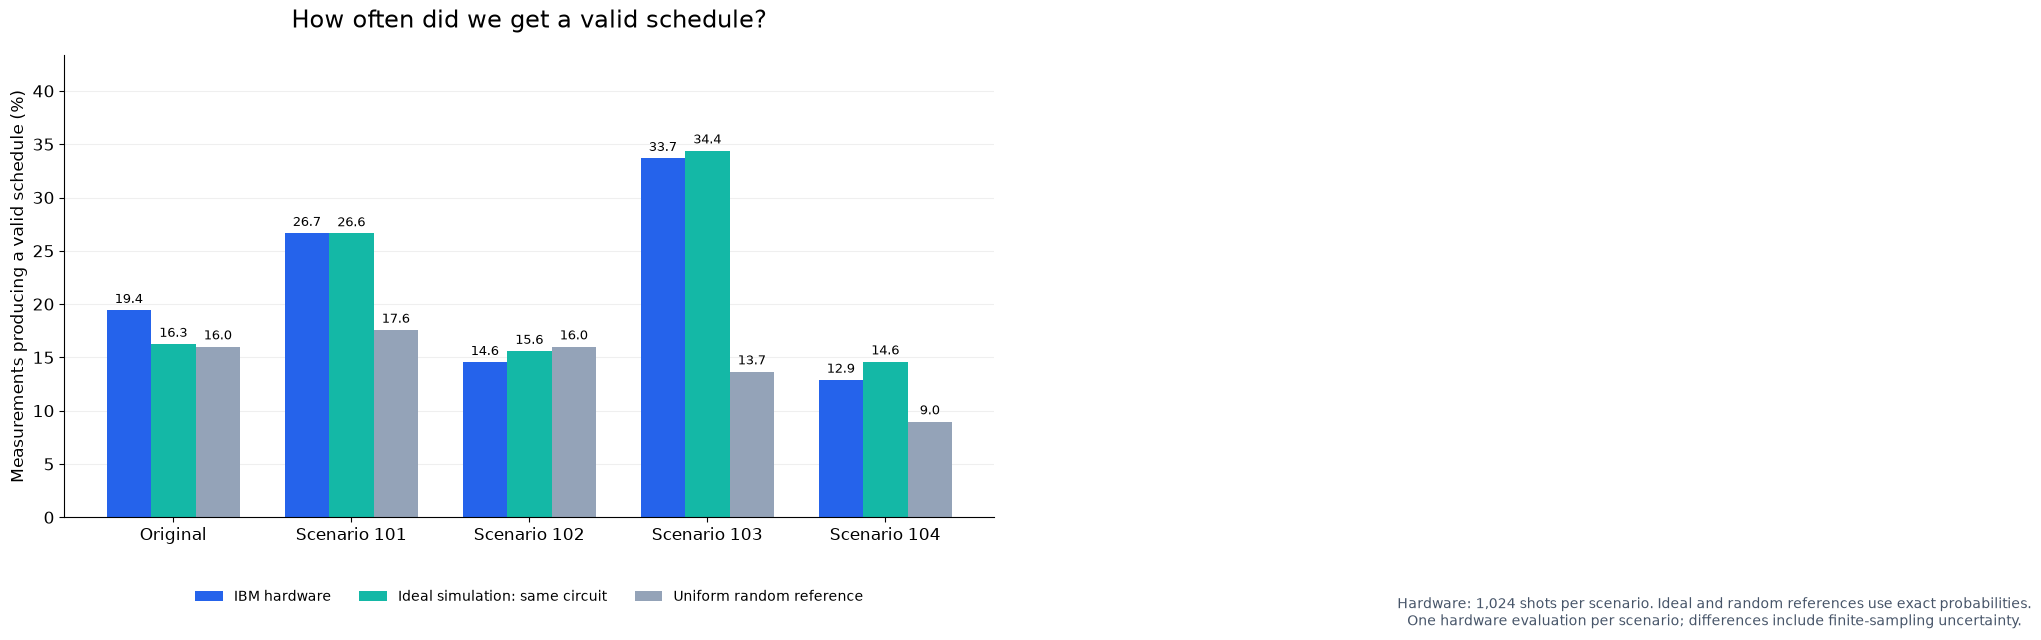

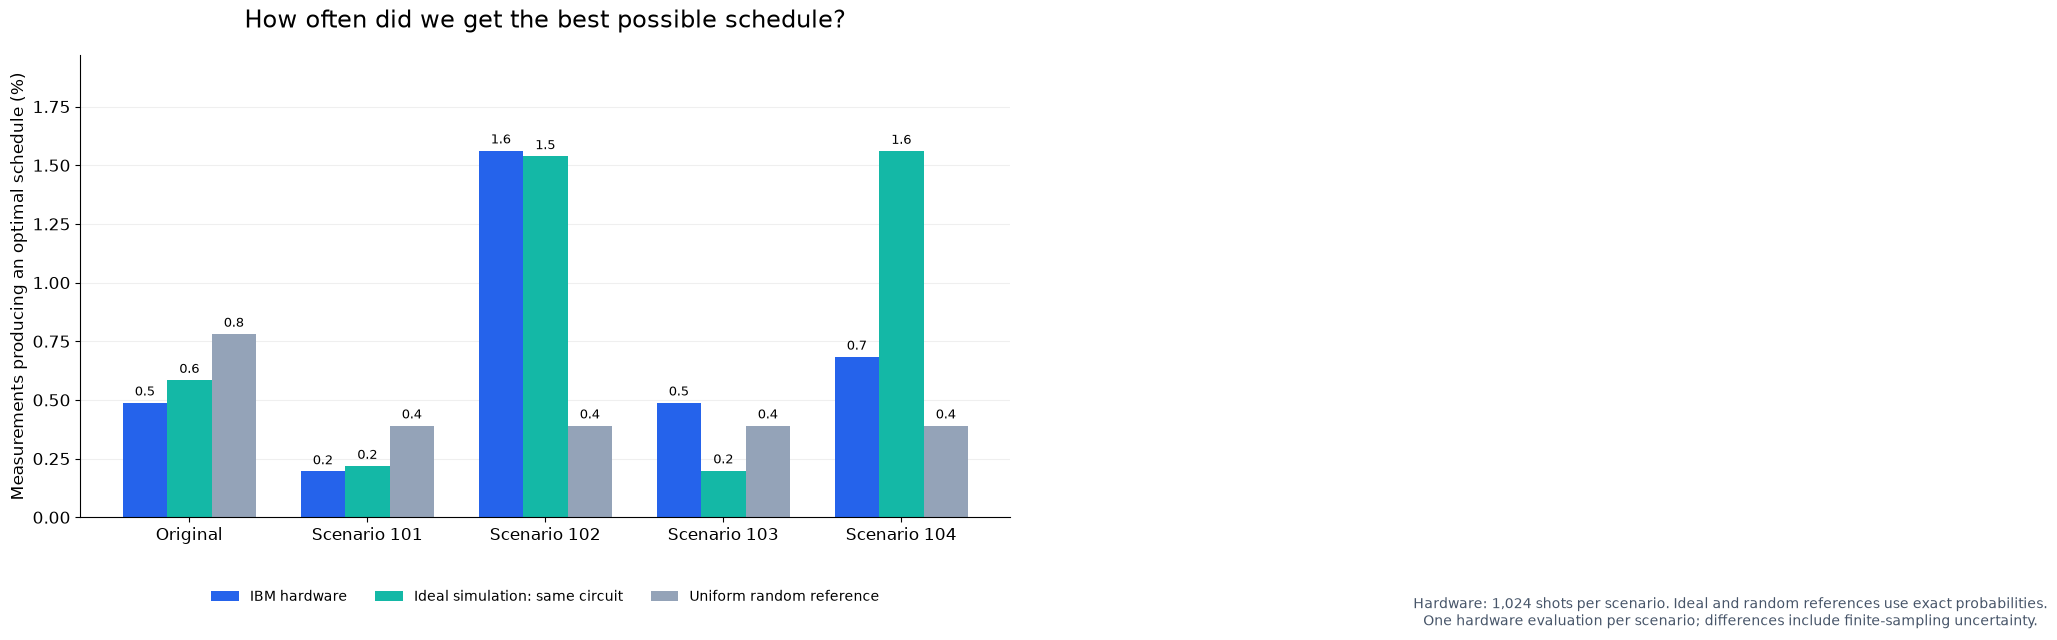

In [25]:
scenario_order = [
    scenario["name"] for scenario in manifest["scenarios"]
]
short_labels = [
    "Original", "Scenario 101", "Scenario 102",
    "Scenario 103", "Scenario 104",
]

methods = [
    ("hardware", "IBM hardware", "#2563EB"),
    ("ideal", "Ideal simulation: same circuit", "#14B8A6"),
    ("uniform", "Uniform random reference", "#94A3B8"),
]

x = np.arange(len(scenario_order))
width = 0.25

for metric, title, ylabel, filename in [
    (
        "feasible_probability",
        "How often did we get a valid schedule?",
        "Measurements producing a valid schedule (%)",
        "01_valid_schedules",
    ),
    (
        "optimal_probability",
        "How often did we get the best possible schedule?",
        "Measurements producing an optimal schedule (%)",
        "02_optimal_schedules",
    ),
]:
    fig, ax = plt.subplots(figsize=(12, 6))

    for j, (method, label, color) in enumerate(methods):
        values = [
            100 * results[name][method][metric]
            for name in scenario_order
        ]
        bars = ax.bar(
            x + (j - 1) * width,
            values,
            width,
            label=label,
            color=color,
        )
        ax.bar_label(
            bars,
            labels=[f"{v:.1f}" for v in values],
            padding=3,
            fontsize=9,
        )

    ax.set_xticks(x, short_labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=20)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        ncol=3,
        frameon=False,
        fontsize=10,
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    fig.text(
        1.5, -0.07,
        "Hardware: 1,024 shots per scenario. "
        "Ideal and random references use exact probabilities.\n"
        "One hardware evaluation per scenario; "
        "differences include finite-sampling uncertainty.",
        ha="center", fontsize=10, color="#475569",
    )

    save_slide_figure(fig, filename)

BEST VALID SCHEDULE OBSERVED ON HARDWARE


,Scenario,Task ID,Task,Satellite,Start,End,Priority points,Decision
0,Original disaster scenario,T0,War Zone Alpha — infrastructure damage,SAT_A,0,3,9,Selected
1,Original disaster scenario,T1,Red Sea shipping lane — cargo flow,SAT_A,2,5,4,Not selected
2,Original disaster scenario,T2,War Zone Alpha — second pass,SAT_B,4,7,6,Not selected
3,Original disaster scenario,T3,California wildfire — fire perimeter,SAT_B,6,9,8,Selected
4,Original disaster scenario,T4,Red Sea shipping lane — second pass,SAT_C,1,4,5,Selected
5,Original disaster scenario,T5,California wildfire — burn scar,SAT_C,8,11,7,Not selected
6,Original disaster scenario,T6,War Zone Alpha — late pass,SAT_A,10,13,6,Not selected
7,Original disaster scenario,T7,California wildfire — final pass,SAT_C,12,15,8,Not selected
8,Generated scenario 101,T0,Wildfire East,SAT_C,4,7,2,Not selected
9,Generated scenario 101,T1,Wildfire East,SAT_B,5,7,5,Not selected


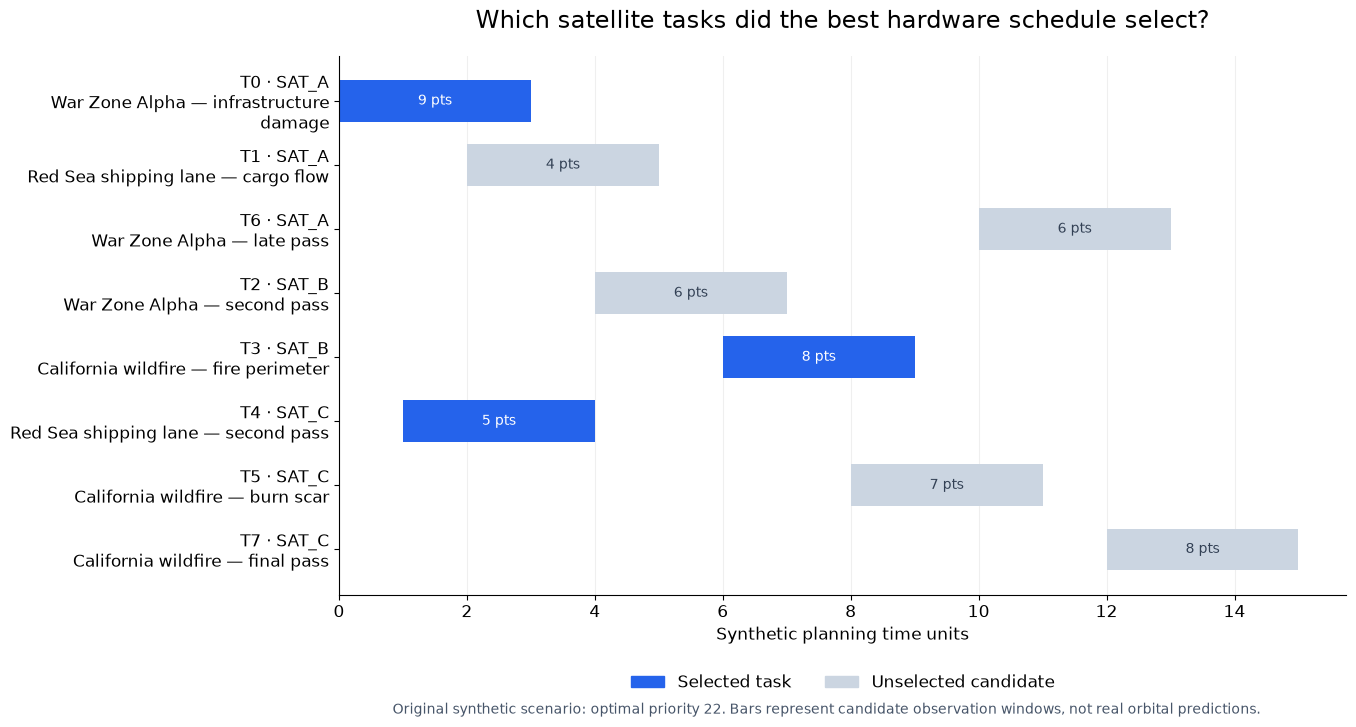

In [23]:
schedule_rows = []

for scenario in manifest["scenarios"]:
    name = scenario["name"]
    schedule = results[name]["hardware"]["best_schedule"]

    for task in scenario["tasks"]:
        schedule_rows.append({
            "Scenario": scenario_labels.get(name, name),
            "Task ID": task["id"],
            "Task": task.get(
                "name",
                task["target"].replace("_", " "),
            ),
            "Satellite": task["sat"],
            "Start": task["t0"],
            "End": task["t1"],
            "Priority points": task["priority"],
            "Decision": (
                "Selected"
                if schedule[task["id"]]
                else "Not selected"
            ),
        })

schedule_table = pd.DataFrame(schedule_rows)

print("BEST VALID SCHEDULE OBSERVED ON HARDWARE")
display(schedule_table)

schedule_table.to_csv(
    SLIDES / "all_task_decisions.csv", index=False
)

original = next(
    s for s in manifest["scenarios"]
    if s["name"] == "original"
)
original_schedule = results["original"]["hardware"]["best_schedule"]
tasks = sorted(
    original["tasks"],
    key=lambda task: (task["sat"], task["t0"]),
)

fig, ax = plt.subplots(figsize=(13, 7))
labels = []

for y, task in enumerate(tasks):
    selected = bool(original_schedule[task["id"]])
    color = "#2563EB" if selected else "#CBD5E1"

    ax.barh(
        y,
        task["t1"] - task["t0"],
        left=task["t0"],
        height=0.65,
        color=color,
    )

    ax.text(
        (task["t0"] + task["t1"]) / 2,
        y,
        f"{task['priority']} pts",
        ha="center", va="center",
        color="white" if selected else "#334155",
        fontsize=10,
    )

    task_name = task.get(
        "name", task["target"].replace("_", " ")
    )
    labels.append(
        f"{task['id']} · {task['sat']}\n"
        + textwrap.fill(task_name, width=36)
    )

ax.set_yticks(range(len(tasks)), labels)
ax.invert_yaxis()
ax.set_xlabel("planning time(seconds)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(
    "Which satellite tasks did the best hardware schedule select?",
    pad=20,
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#2563EB", label="Selected task"),
        Patch(color="#CBD5E1", label="Unselected candidate"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
)

fig.text(
    0.5, -0.06,
    "Original synthetic scenario: optimal priority 22. "
    "Bars represent candidate observation windows",
    ha="center", fontsize=10, color="#475569",
)

save_slide_figure(fig, "03_original_task_timeline")

In [24]:
conflict_rows = []

for scenario in manifest["scenarios"]:
    task_lookup = {
        task["id"]: task for task in scenario["tasks"]
    }

    for a_id, b_id in scenario["conflicts"]:
        a = task_lookup[a_id]
        b = task_lookup[b_id]

        overlap = (
            a["t0"] < b["t1"]
            and b["t0"] < a["t1"]
        )
        reasons = []

        if overlap and a["sat"] == b["sat"]:
            reasons.append("Same satellite, overlapping times")

        if overlap and a["gs"] == b["gs"]:
            reasons.append("Same ground station, overlapping times")

        if a["target"] == b["target"]:
            reasons.append(
                "At most one observation per target "
                "(model policy)"
            )

        conflict_rows.append({
            "Scenario": scenario_labels.get(
                scenario["name"], scenario["name"]
            ),
            "Task A": a.get("name", a_id),
            "Task B": b.get("name", b_id),
            "Why they conflict": "; ".join(reasons),
        })

conflict_table = pd.DataFrame(conflict_rows)

print("Can't SCHEDULE EVERYTHING?")
display(
    conflict_table[
        conflict_table["Scenario"]
        == "Original disaster scenario"
    ]
)

conflict_table.to_csv(
    SLIDES / "conflict_explanations.csv", index=False)


print(SLIDES)

WHY CAN'T WE SCHEDULE EVERYTHING?


,Scenario,Task A,Task B,Why they conflict
0,Original disaster scenario,War Zone Alpha — infrastructure damage,Red Sea shipping lane — cargo flow,"Same satellite, overlapping times; Same ground..."
1,Original disaster scenario,War Zone Alpha — infrastructure damage,War Zone Alpha — second pass,At most one observation per target (model policy)
2,Original disaster scenario,War Zone Alpha — infrastructure damage,War Zone Alpha — late pass,At most one observation per target (model policy)
3,Original disaster scenario,Red Sea shipping lane — cargo flow,Red Sea shipping lane — second pass,At most one observation per target (model policy)
4,Original disaster scenario,War Zone Alpha — second pass,California wildfire — fire perimeter,"Same satellite, overlapping times; Same ground..."
5,Original disaster scenario,War Zone Alpha — second pass,War Zone Alpha — late pass,At most one observation per target (model policy)
6,Original disaster scenario,California wildfire — fire perimeter,California wildfire — burn scar,At most one observation per target (model policy)
7,Original disaster scenario,California wildfire — fire perimeter,California wildfire — final pass,At most one observation per target (model policy)
8,Original disaster scenario,California wildfire — burn scar,California wildfire — final pass,At most one observation per target (model policy)



Presentation files saved in:
/Users/drsweetyramnani/Documents/Research_Projects/Quantum/presentation_results
